# 04 · Evaluation

We have 45 recordings: 12 each for standing, walking and still, and 9 for jumping. That is too
few for a single train/test split to be reliable, so we use **4-fold cross-validation by
recording**. Each fold holds out 2–3 recordings of every activity (11–12 in total), and the
model (scaler + HMM) is trained on the remaining 33–34. Every window is therefore predicted by
a model that never saw its recording. Each held-out recording is decoded with Viterbi as its
own sequence.

In [1]:
# --- Environment setup (works locally and in Google Colab) ---
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/Orrie-Dan/Human-Activity-HMM.git"
    ROOT = Path("/content/human-activity-hmm")
    if not ROOT.exists():
        !git clone -q {REPO_URL} {ROOT}
    %cd {ROOT}
    !pip install -q -r requirements.txt
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Raw recordings are not in git. In Colab, upload a zip whose top level holds the
# p01_<activity>_<nn>/ folders and metadata.csv (i.e. the contents of data/raw/).
RAW = ROOT / "data" / "raw"
if IN_COLAB and not any(RAW.glob("p*_*_*")):
    import io, zipfile
    from google.colab import files
    for name, content in files.upload().items():
        zipfile.ZipFile(io.BytesIO(content)).extractall(RAW)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import apply_style

apply_style()
pd.set_option("display.precision", 3)


In [3]:
from src.dataset import build_feature_table

if config.FEATURES_FILE.exists():
    table = pd.read_csv(config.FEATURES_FILE)
else:  # build it if notebook 02 has not been run
    table, _ = build_feature_table()
    config.FEATURES_FILE.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(config.FEATURES_FILE, index=False)
print(f"{len(table)} windows from {table['recording'].nunique()} recordings")


321 windows from 45 recordings


## Predictions on held-out data

In [4]:
from src.training import cross_validate, recording_folds

for i, fold in enumerate(recording_folds(table, config.DEFAULT_HMM_CONFIG.n_folds)):
    print(f"fold {i}: test = {fold}")
results = cross_validate(table)
results.head()

fold 0: test = ['p01_jumping_01', 'p01_jumping_05', 'p01_jumping_09', 'p01_standing_01', 'p01_standing_05', 'p01_standing_09', 'p01_still_01', 'p01_still_05', 'p01_still_09', 'p01_walking_01', 'p01_walking_05', 'p01_walking_09']
fold 1: test = ['p01_jumping_02', 'p01_jumping_06', 'p01_standing_02', 'p01_standing_06', 'p01_standing_10', 'p01_still_02', 'p01_still_06', 'p01_still_10', 'p01_walking_02', 'p01_walking_06', 'p01_walking_10']
fold 2: test = ['p01_jumping_03', 'p01_jumping_07', 'p01_standing_03', 'p01_standing_07', 'p01_standing_11', 'p01_still_03', 'p01_still_07', 'p01_still_11', 'p01_walking_03', 'p01_walking_07', 'p01_walking_11']
fold 3: test = ['p01_jumping_04', 'p01_jumping_08', 'p01_standing_04', 'p01_standing_08', 'p01_standing_12', 'p01_still_04', 'p01_still_08', 'p01_still_12', 'p01_walking_04', 'p01_walking_08', 'p01_walking_12']


,recording,participant,activity,window_index,window_start_s,fold,supervised,baum_welch
0,p01_jumping_01,p01,jumping,0,0.0,0,jumping,jumping
1,p01_jumping_01,p01,jumping,1,0.5,0,jumping,jumping
2,p01_jumping_01,p01,jumping,2,1.0,0,jumping,jumping
3,p01_jumping_01,p01,jumping,3,1.5,0,jumping,jumping
4,p01_jumping_01,p01,jumping,4,2.0,0,jumping,jumping


## Metrics and confusion matrix

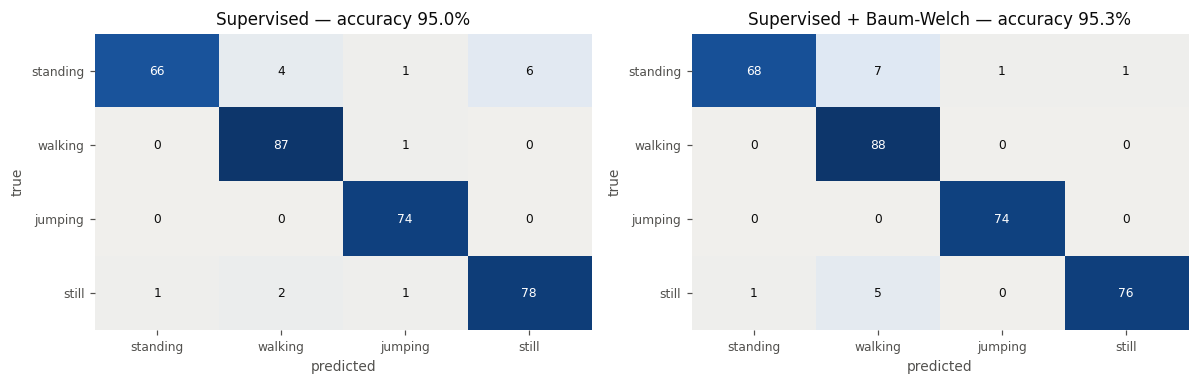

In [5]:
from src.evaluation import evaluate
from src.visualization import plot_matrix

VARIANTS = {"supervised": "Supervised", "baum_welch": "Supervised + Baum-Welch"}
metrics = {v: evaluate(results["activity"], results[v], config.ACTIVITIES) for v in VARIANTS}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (v, title) in zip(axes, VARIANTS.items()):
    plot_matrix(metrics[v]["confusion"], f"{title} — accuracy {metrics[v]['accuracy']:.1%}",
                fmt="{:.0f}", ax=ax, xlabel="predicted", ylabel="true")
fig.tight_layout()

In [6]:
pd.concat({VARIANTS[v]: m["per_class"] for v, m in metrics.items()}, axis=1)

Supervised                                       \
         sensitivity specificity precision     f1 support   
true                                                        
standing       0.857       0.996     0.985  0.917      77   
walking        0.989       0.974     0.935  0.961      88   
jumping        1.000       0.988     0.961  0.980      74   
still          0.951       0.975     0.929  0.940      82   

         Supervised + Baum-Welch                                       
                     sensitivity specificity precision     f1 support  
true                                                                   
standing                   0.883       0.996     0.986  0.932      77  
walking                    1.000       0.948     0.880  0.936      88  
jumping                    1.000       0.996     0.987  0.993      74  
still                      0.927       0.996     0.987  0.956      82

Accuracy per held-out recording (only recordings with any error are shown):

In [7]:
per_recording = pd.DataFrame({
    v: (results["activity"] == results[v]).groupby(results["recording"]).mean() for v in VARIANTS
})
per_recording[(per_recording < 1).any(axis=1)]

,supervised,baum_welch
recording,,
p01_standing_01,0.300,0.500
p01_standing_05,0.750,0.000
p01_standing_07,0.250,1.000
p01_still_01,0.889,0.778
p01_still_02,0.846,0.769
p01_still_05,0.750,0.750
p01_walking_03,0.929,1.000


### Where the errors happen

Viterbi paths for the recordings with errors (gray band = true activity, dots = prediction):

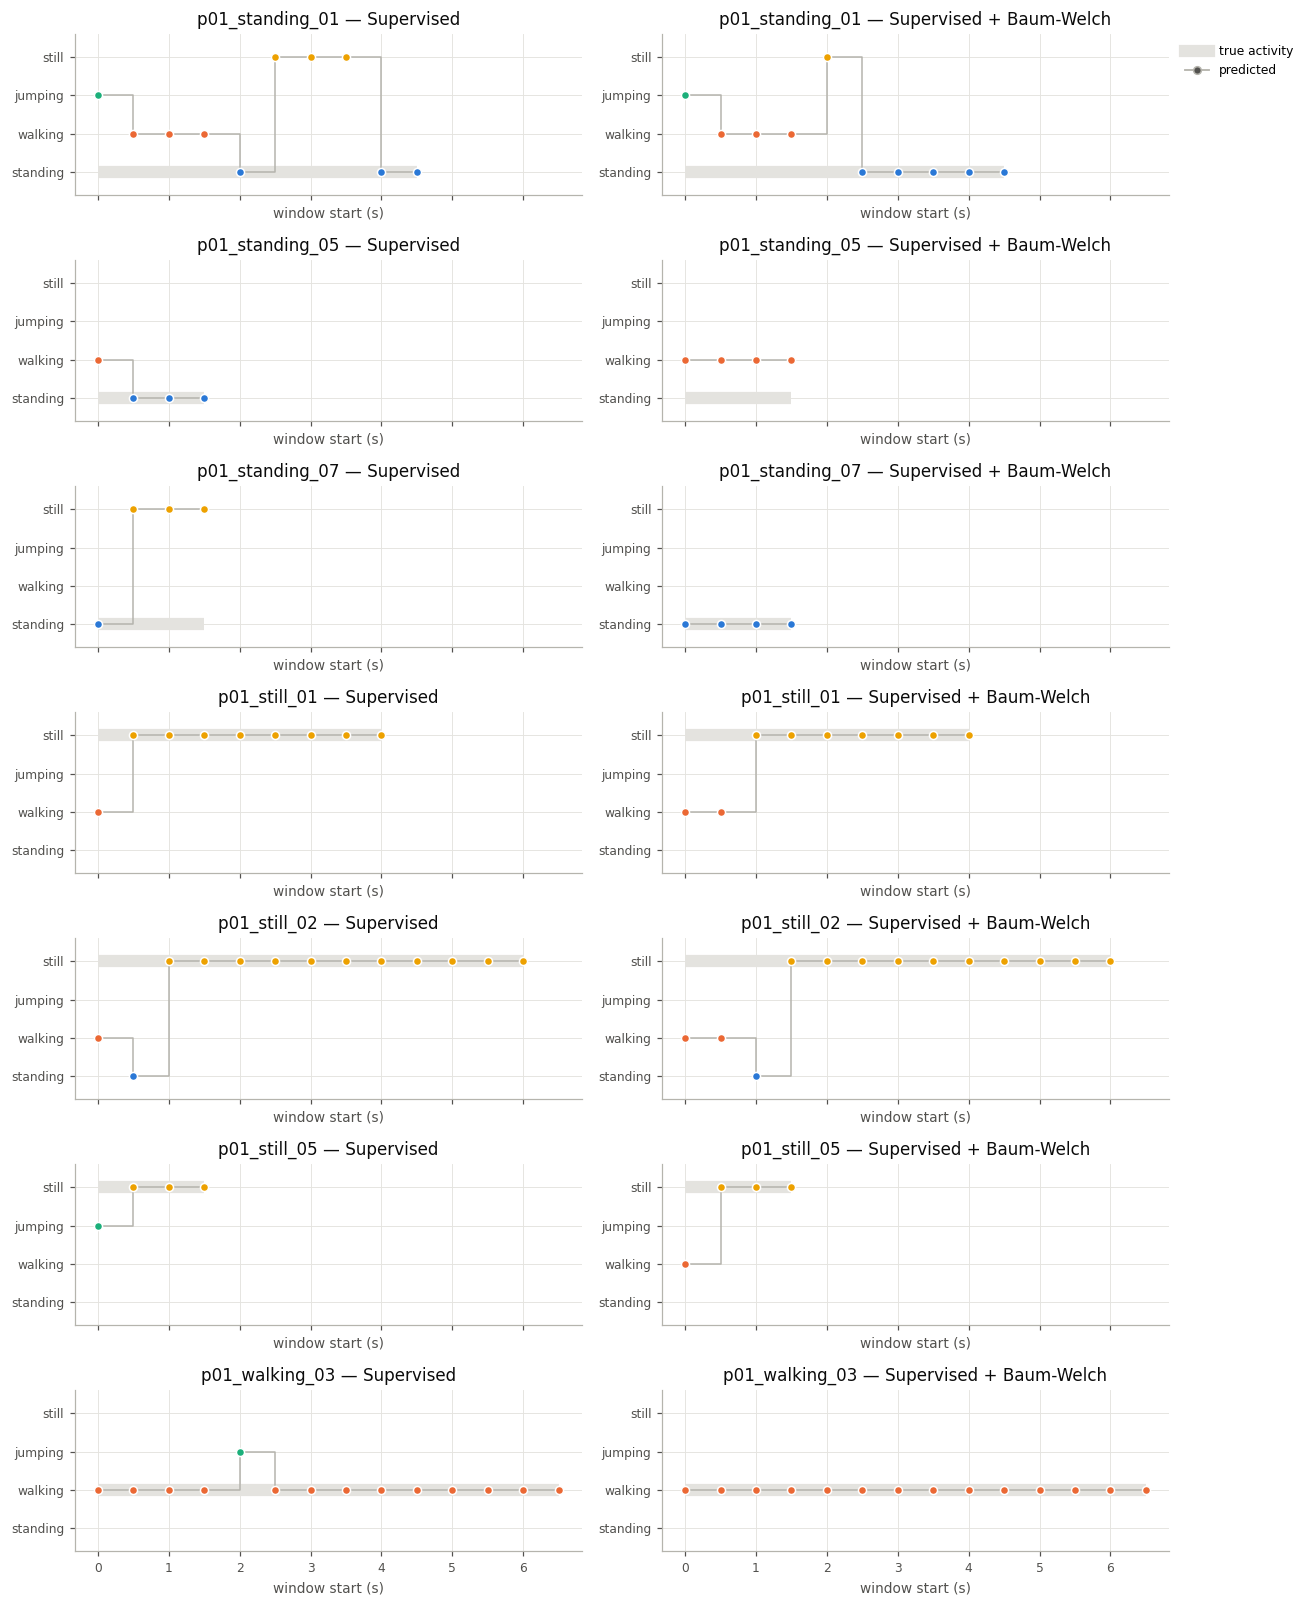

In [8]:
from src.visualization import plot_decoded

names = per_recording[(per_recording < 1).any(axis=1)].index.tolist()
fig, axes = plt.subplots(len(names), 2, figsize=(12, 2.1 * len(names)), sharex=True)
for row, name in enumerate(names):
    seq = results[results["recording"] == name].sort_values("window_index")
    for col, (v, title) in enumerate(VARIANTS.items()):
        plot_decoded(seq["window_start_s"], seq["activity"], seq[v], f"{name} — {title}",
                     ax=axes[row, col], legend=(row == 0 and col == 1))
fig.tight_layout()

### Unseen sequence with activity changes

None of our recordings contains a change of activity. To check whether the model can follow
one, we take fold 0, train on the recordings of the other three folds, and **concatenate the
held-out recordings into one sequence**. We interleave the activities
(still → standing → walking → jumping, three times), which gives 11 activity changes.

This is an artificial test: the joins are abrupt rather than real transitions.

held out: ['p01_still_01', 'p01_standing_01', 'p01_walking_01', 'p01_jumping_01', 'p01_still_05', 'p01_standing_05', 'p01_walking_05', 'p01_jumping_05', 'p01_still_09', 'p01_standing_09', 'p01_walking_09', 'p01_jumping_09']


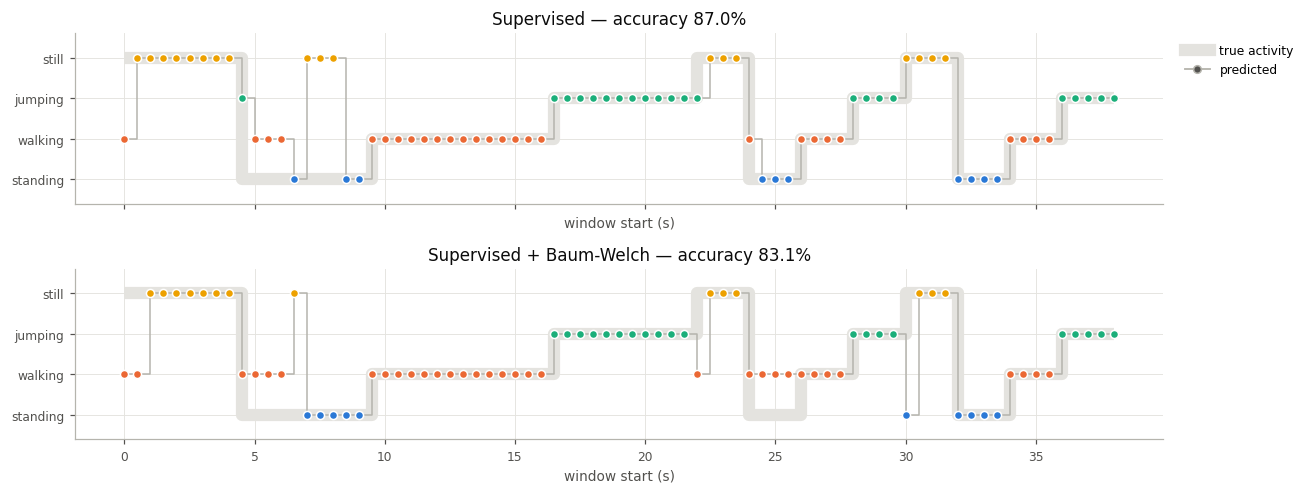

In [9]:
from src.training import train_model, predict

fold0 = recording_folds(table, config.DEFAULT_HMM_CONFIG.n_folds)[0]
order = ["still", "standing", "walking", "jumping"]
by_activity = {a: sorted(r for r in fold0 if r.split("_")[1] == a) for a in order}
n_rounds = max(len(v) for v in by_activity.values())
test_recs = [by_activity[a][i] for i in range(n_rounds) for a in order if i < len(by_activity[a])]
train = table[~table["recording"].isin(fold0)]

parts = [table[table["recording"] == r].sort_values("window_index") for r in test_recs]
combined = pd.concat(parts).assign(recording="combined", window_index=lambda d: np.arange(len(d)))
combined["window_start_s"] = combined["window_index"] * config.DEFAULT_FEATURE_CONFIG.step_s

fig, axes = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True)
for ax, (v, title) in zip(axes, VARIANTS.items()):
    model = train_model(train, baum_welch=(v == "baum_welch"))
    pred = predict(model, combined)
    acc = (pred == combined["activity"]).mean()
    plot_decoded(combined["window_start_s"], combined["activity"], pred,
                 f"{title} — accuracy {acc:.1%}", ax=ax, legend=(ax is axes[0]))
fig.tight_layout()
print("held out:", test_recs)

Both models follow most of the 11 switches, usually on exactly the right window. The supervised
model labels 87.0 % of windows correctly and the refined model 83.1 %. Almost all errors fall in
three flagged recordings that happen to be in fold 0:

- `p01_still_01`: the handling at the start of still is read as walking.
- `p01_standing_01`: the bump is read as walking (and, for the supervised model, briefly as
  jumping and still).
- `p01_standing_05`: the refined model labels this whole short segment as walking.

Here the supervised model does better, the opposite of the cross-validation result. On one
sequence of 77 windows, that is a difference of 3 windows, so neither ranking should be
read too much into.

## Transition/emission analysis

How much do transitions matter compared with emissions? For each window we compare the
best and second-best state's emission log-likelihood. A switch costs about
$\log(A_{kk}/A_{kj}) = \log(0.96/0.014) \approx 4.2$ nats in the supervised model. Only windows
whose emission gap is smaller than that can be changed by the transition matrix.

In [10]:
model = train_model(table)
X = model.scaler.transform(table[model.feature_columns].to_numpy(dtype=float))
log_b = np.sort(model.hmm.log_emission(X), axis=1)
gap = log_b[:, -1] - log_b[:, -2]
A = model.hmm.transmat
switch_cost = np.log(np.diag(A).mean() / A[~np.eye(len(A), dtype=bool)].mean())
print(f"switch cost: {switch_cost:.1f} nats")
print(f"emission gap between best and 2nd-best state: median {np.median(gap):.0f} nats, "
      f"10th percentile {np.percentile(gap, 10):.1f}")
print(f"windows where transitions can change the decision (gap < cost): {(gap < switch_cost).mean():.1%}")

switch cost: 4.2 nats
emission gap between best and 2nd-best state: median 153 nats, 10th percentile 25.0
windows where transitions can change the decision (gap < cost): 0.6%


Emissions dominate. The median gap is about 150 nats, roughly 35 times the switch cost, and only
2 of 321 windows (0.6 %) are close enough for the transition matrix to change the decision. So the
HMM behaves almost like a per-window Gaussian classifier, and the transitions only smooth a
handful of borderline windows. This is a consequence of using 56 features, each adding its own
term to the log-likelihood.

These gaps are measured on the training data (model fitted on all windows). On held-out windows
they are smaller, so transitions matter somewhat more there.

## Discussion

**Results.** Cross-validated by recording over 45 recordings (321 windows), the supervised HMM
classifies **95.0 %** of windows correctly, and **95.3 %** after Baum-Welch refinement. Jumping is
never missed. Walking is almost never missed either (sensitivity 0.99 / 1.00), but it attracts
false positives (precision 0.94 / 0.88): disturbed standing and still windows tend to be called
walking.

**More data helped.** With only the first 16 recordings, accuracy was 91.7 % (supervised) and
95.6 % (refined). Adding the second batch raised the supervised model by about 3 points. For
example, `p01_standing_03`, half mislabeled before, is now fully correct. The gap between the
two variants shrank from about 4 points to 0.3.

**Errors are explainable.** In the refined model, every error comes from the five recordings we
flagged for handling during collection:

- `p01_standing_01`: the mid-recording bump makes standing windows look like walking.
- `p01_still_01`, `_02`, `_05`, `p01_standing_05`: the phone was still being handled after the
  1 s trim, so the first windows look like walking or standing. `p01_standing_05` is so short
  (4 windows) that the refined model labels all of it as walking.

The supervised model also labels 3 of the 4 windows of `p01_standing_07` as still. Its tremor is
close to the still/standing boundary, and with 56 partly redundant features, a few features vote
several times. Baum-Welch re-estimates the variances and fixes this.

**Limitations.**

- One participant and one phone, recorded in two sessions, with 9–12 recordings per activity.
  The results are optimistic for other people or devices.
- The second batch is short (5–7 s), so after trimming it gives only 2–6 windows per recording.
  Handling at the start then affects a large share of the recording.
- The transition matrix is not learned from real activity changes. It comes from the
  pseudocount (supervised), or from windows that EM reassigns inside recordings (Baum-Welch).
  The concatenated test shows that both models can follow changes, but its joins are
  artificial. It is not a substitute for recordings that contain real transitions.
- With 56 features, emissions outweigh transitions for over 99 % of windows, so the
  sequence model adds little over a per-window classifier on this data.
- Baum-Welch is used semi-supervised (initialized from labels). Fully unsupervised EM would
  need an explicit mapping from states to activities.
- Overlapping windows are correlated, so the window count overstates the effective sample size.

**Possible improvements.**

- Record sessions with several activities in sequence, to learn and test real transitions.
- Collect more participants and devices, and use leave-one-participant-out evaluation.
- Use a smaller feature set (e.g. drop `dom_freq` for low-motion channels) or apply PCA, which
  would reduce the redundant evidence of the diagonal model.
- Add gravity-including acceleration (`AccelerometerUncalibrated.csv`) to capture phone
  orientation.